## High_Cardinality_Encoding_Comparison

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data=pd.read_csv(r"C:\Users\keert\OneDrive\Documents\ride_hailing.csv")
data


,Unnamed: 0,driver_id,pickup_zip,dropoff_zip,vehicle_model,hour,distance_mi,fare,wait_min,complained
0,0,D0267,Z0446,Z1391,Luxury,4,7.62,11.94,7.82,0
1,1,D0462,Z0355,Z0769,SUV,3,5.98,9.63,4.89,0
2,2,D0021,Z1077,Z0303,Sedan,22,4.68,7.86,3.88,1
3,3,D0055,Z0181,Z1311,SUV,14,9.02,13.60,5.81,0
4,4,D0165,Z1213,Z0042,EV,11,5.22,8.44,2.30,1
...,...,...,...,...,...,...,...,...,...,...
29995,29995,D0561,Z0395,Z0666,Sedan,3,6.78,11.17,8.46,0
29996,29996,D0085,Z0882,Z1468,Sedan,20,3.81,7.00,4.20,0
29997,29997,D0498,Z1282,Z0598,EV,2,2.66,5.76,11.41,1
29998,29998,D0026,Z0529,Z1477,Sedan,22,4.20,6.88,8.66,0


In [ ]:
df=data.copy()

In [ ]:
df.head()

,Unnamed: 0,driver_id,pickup_zip,dropoff_zip,vehicle_model,hour,distance_mi,fare,wait_min,complained
0,0,D0267,Z0446,Z1391,Luxury,4,7.62,11.94,7.82,0
1,1,D0462,Z0355,Z0769,SUV,3,5.98,9.63,4.89,0
2,2,D0021,Z1077,Z0303,Sedan,22,4.68,7.86,3.88,1
3,3,D0055,Z0181,Z1311,SUV,14,9.02,13.60,5.81,0
4,4,D0165,Z1213,Z0042,EV,11,5.22,8.44,2.30,1


In [ ]:
df.shape

(30000, 10)

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     30000 non-null  int64  
 1   driver_id      30000 non-null  str    
 2   pickup_zip     30000 non-null  str    
 3   dropoff_zip    30000 non-null  str    
 4   vehicle_model  30000 non-null  str    
 5   hour           30000 non-null  int64  
 6   distance_mi    30000 non-null  float64
 7   fare           30000 non-null  float64
 8   wait_min       30000 non-null  float64
 9   complained     30000 non-null  int64  
dtypes: float64(3), int64(3), str(4)
memory usage: 2.3 MB


In [ ]:
df.describe()

,Unnamed: 0,hour,distance_mi,fare,wait_min,complained
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000
mean,14999.500000,11.538300,6.044082,9.749576,5.117527,0.160033
std,8660.398374,6.926928,2.897033,3.513787,2.800641,0.366643
min,0.000000,0.000000,0.500000,1.610000,0.000000,0.000000
25%,7499.750000,6.000000,3.960000,7.230000,3.000000,0.000000
50%,14999.500000,12.000000,5.970000,9.650000,5.000000,0.000000
75%,22499.250000,18.000000,8.020000,12.140000,7.030000,0.000000
max,29999.000000,23.000000,18.090000,24.440000,18.760000,1.000000


In [ ]:
df.isnull().sum()

Unnamed: 0       0
driver_id        0
pickup_zip       0
dropoff_zip      0
vehicle_model    0
hour             0
distance_mi      0
fare             0
wait_min         0
complained       0
dtype: int64

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.nunique()

Unnamed: 0       30000
driver_id          600
pickup_zip        1500
dropoff_zip       1500
vehicle_model        5
hour                24
distance_mi       1435
fare              1790
wait_min          1371
complained           2
dtype: int64

In [ ]:
df.drop(columns=['Unnamed: 0'], inplace=True)

In [ ]:
numeric_col=df.select_dtypes(include=['int64','float64'])
cat_col=df.select_dtypes(include=['str'])
print(numeric_col.columns)
print(cat_col.columns)

Index(['hour', 'distance_mi', 'fare', 'wait_min', 'complained'], dtype='str')
Index(['driver_id', 'pickup_zip', 'dropoff_zip', 'vehicle_model'], dtype='str')


Train-Test-split the data

In [ ]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=['complained'])
y=df['complained']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [ ]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(24000, 8)
(6000, 8)
(24000,)
(6000,)


In [ ]:
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

complained
0    0.839958
1    0.160042
Name: proportion, dtype: float64
complained
0    0.84
1    0.16
Name: proportion, dtype: float64


In [ ]:
from sklearn.preprocessing import OneHotEncoder
encoder=OneHotEncoder(max_categories=20,handle_unknown='infrequent_if_exist')

Identified categorical and numerical features in the dataset.
Applied One-Hot Encoding to convert categorical variables into numerical binary columns.
Created separate encoded training and testing datasets using fit_transform() and transform().
Combined the encoded categorical features with the numerical features.
Trained a LightGBM classifier using the One-Hot Encoded dataset.
Evaluated the model using accuracy, precision, recall, F1-score and confusion matrix.

In [ ]:
numeric_col = X_train.select_dtypes(
    include=['number']
).columns.tolist()

cat_col = X_train.select_dtypes(
    include=['object', 'category', 'str']
).columns.tolist()

hstack means Horizontal Stack.

It combines two datasets side by side (column-wise).

Why do we need it?

Because we have two separate datasets after preprocessing:
1. Numerical columns.
2. One-Hot Encoded categorical columns.
We need to combine them before giving the data to LightGBM.

CSR stands for Compressed Sparse Row.

It converts the combined data into CSR sparse matrix format.

Why?

One-Hot Encoding produces many zeros. Sparse matrices store data efficiently by avoiding storage of most zero values.

In [ ]:
X_train_encoded = encoder.fit_transform(X_train[cat_col])

X_test_encoded = encoder.transform(X_test[cat_col])
from scipy.sparse import hstack

X_train_final = hstack([
    X_train[numeric_col].values,
    X_train_encoded
]).tocsr()

X_test_final = hstack([
    X_test[numeric_col].values,
    X_test_encoded
]).tocsr()
print("Before encoding:", X_train.shape)
print("After encoding:", X_train_final.shape)

Before encoding: (24000, 8)
After encoding: (24000, 69)


In [ ]:
import sys
print(sys.executable)
print(sys.version)

c:\Users\keert\AppData\Local\Programs\Python\Python312\python.exe
3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


In [ ]:
import sys
!{sys.executable} -m pip install lightgbm


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [ ]:
lgbm = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42,
    class_weight='balanced'
)
print(lgbm.fit(X_train_final, y_train))
print("Model trained successfully!")

[LightGBM] [Info] Number of positive: 3841, number of negative: 20159
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004546 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 919
[LightGBM] [Info] Number of data points in the train set: 24000, number of used features: 69
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
LGBMClassifier(class_weight='balanced', random_state=42)
Model trained successfully!


In [ ]:
y_pred_lgbm = lgbm.predict(X_test_final)

print(y_pred_lgbm[:20])

[0 0 1 1 1 0 1 0 1 1 0 0 0 1 0 1 0 1 0 1]


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred_lgbm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lgbm))

Accuracy: 0.6238333333333334

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.67      0.75      5040
           1       0.19      0.40      0.25       960

    accuracy                           0.62      6000
   macro avg       0.52      0.53      0.50      6000
weighted avg       0.75      0.62      0.67      6000



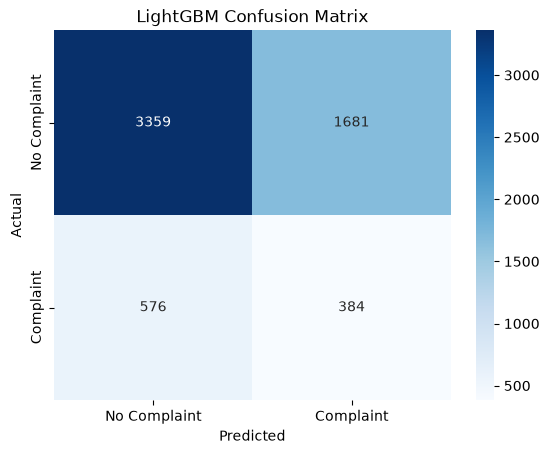

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_lgbm = confusion_matrix(y_test, y_pred_lgbm)

sns.heatmap(
    cm_lgbm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Complaint', 'Complaint'],
    yticklabels=['No Complaint', 'Complaint']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('LightGBM Confusion Matrix')
plt.show()

Experiment 2: Frequency Encoding + LightGBM
Replace each category with its frequency in the training dataset.

Understand:
What is Frequency Encoding?
How is category frequency calculated?
How does frequency encoding reduce the number of columns?
What happens when an unseen category appears in the test dataset?
Train a LightGBM classifier and record its performance.

Calculated the frequency of each category using training data.
Replaced categorical values with their corresponding frequencies.
Assigned zero to unseen categories in the test data.
Trained a LightGBM classifier using the frequency-encoded dataset.
Evaluated the model using accuracy, precision, recall, F1-score and confusion matrix.


In [ ]:
freq_maps = {}

for col in cat_col:
    freq = X_train[col].value_counts(normalize=True)
    freq_maps[col] = freq   

In [ ]:
freq_maps['vehicle_model']

vehicle_model
Sedan     0.447833
SUV       0.297167
EV        0.101042
Luxury    0.084083
XL        0.069875
Name: proportion, dtype: float64

In [ ]:
X_train_freq = X_train.copy()
X_test_freq = X_test.copy()

for col in cat_col:
    X_train_freq[col] = X_train[col].map(freq_maps[col])
    X_test_freq[col] = X_test[col].map(freq_maps[col]).fillna(0)

In [ ]:
print("Before encoding:", X_train.shape)
print("After encoding:", X_train_freq.shape)

print(X_train_freq.head())

Before encoding: (24000, 8)
After encoding: (24000, 8)
       driver_id  pickup_zip  dropoff_zip  vehicle_model  hour  distance_mi  \
23959   0.001667    0.000833     0.001000       0.447833     6         5.95   
29128   0.001958    0.000375     0.000792       0.447833     5         4.32   
3313    0.001458    0.000667     0.000542       0.069875     0         6.09   
8943    0.001958    0.000583     0.000625       0.297167    10         7.88   
856     0.001667    0.000500     0.000708       0.447833    23        13.95   

        fare  wait_min  
23959  10.33      4.32  
29128   7.16      8.58  
3313   10.15      3.82  
8943   11.94      5.88  
856    19.43      0.08  


In [ ]:
from lightgbm import LGBMClassifier

lgbm_freq = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42,
    class_weight='balanced'
)

lgbm_freq.fit(X_train_freq, y_train)

[LightGBM] [Info] Number of positive: 3841, number of negative: 20159
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000658 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 887
[LightGBM] [Info] Number of data points in the train set: 24000, number of used features: 8
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000


,class_weight,'balanced'
,random_state,42
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,min_split_gain,0.0
,min_child_weight,0.001


In [ ]:
y_pred_freq = lgbm_freq.predict(X_test_freq)

print(y_pred_freq[:20])

[0 0 1 1 1 0 1 0 1 1 0 0 1 1 0 1 0 1 0 0]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred_freq))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_freq))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_freq))

Accuracy: 0.634

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.68      0.76      5040
           1       0.20      0.42      0.27       960

    accuracy                           0.63      6000
   macro avg       0.53      0.55      0.51      6000
weighted avg       0.75      0.63      0.68      6000


Confusion Matrix:
[[3402 1638]
 [ 558  402]]


Experiment 3: Target / Mean Encoding + LightGBM
Replace each category with the mean of the target variable for that category.

Understand:
What is Target Encoding?
How is the mean target value calculated?
What is the global mean?
How are unseen categories handled?
What is target leakage, and why can it be a problem?
Train a LightGBM classifier and record its performance.


Target Encoding is a technique that converts categorical values into numerical values using the mean of the target variable for each category.

The global mean is the average of the target variable across the entire training dataset

Target leakage happens when information from the target variable accidentally enters the model's training features in a way that would not be available when making real predictions.

Identified categorical and numerical features in the dataset.
Applied Target Encoding to convert categorical variables into numerical values based on the mean of the target variable (complained).
Used K-Fold cross-validation to encode the training data and avoid target leakage.
Applied smoothing to reduce the effect of categories with fewer records.
Replaced unseen categories in the test data with the global mean of the target variable.
Trained a LightGBM classifier using the Target Encoded dataset.
Evaluated the model using accuracy, precision, recall, F1-score and confusion matrix

In [ ]:
global_mean = y_train.mean()
print("Global Mean:", global_mean)

Global Mean: 0.16004166666666667


alpha is used for smoothing.

Why smoothing?

Suppose a category has only 1 record and its target is 1.

Its mean is 1.0 (100%). But one record is not enough to confidently say that category has a 100% complaint rate.

Smoothing reduces the effect of categories with very few records.

Gloobal Mean-Why do we need it?

We use it as a baseline when calculating smoothed category values and handling unseen categories.


5-Fold-Why do we do this?

To avoid target leakage.

If a category has very few records, its average may not be reliable.
Smoothing pulls that average closer to the global mean.
Alpha controls smoothing.


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold

X_train_te = X_train.copy()
X_test_te = X_test.copy()

global_mean = y_train.mean()

kf = KFold(n_splits=5, shuffle=True, random_state=42)

alpha = 10
for col in cat_col:

    encoded_values = np.zeros(len(X_train))

    for train_idx, val_idx in kf.split(X_train):

        X_fold = X_train.iloc[train_idx]
        y_fold = y_train.iloc[train_idx]

        fold_data = pd.DataFrame({
            'category': X_fold[col].values,
            'target': y_fold.values
        })

        stats = fold_data.groupby('category')['target'].agg(
            ['mean', 'count']
        )

        fold_global_mean = y_fold.mean()

        mapping = (
            (stats['mean'] * stats['count'] +
             fold_global_mean * alpha) /
            (stats['count'] + alpha)
        )

        encoded_values[val_idx] = (
            X_train.iloc[val_idx][col]
            .map(mapping)
            .fillna(fold_global_mean)
            .values
        )

    X_train_te[col] = encoded_values

    full_data = pd.DataFrame({
        'category': X_train[col].values,
        'target': y_train.values
    })

    full_stats = full_data.groupby('category')['target'].agg(
        ['mean', 'count']
    )

    full_mapping = (
        (full_stats['mean'] * full_stats['count'] +
         global_mean * alpha) /
        (full_stats['count'] + alpha)
    )

    X_test_te[col] = (
        X_test[col]
        .map(full_mapping)
        .fillna(global_mean)
    )

In [ ]:
print("Before encoding:", X_train.shape)
print("After encoding:", X_train_te.shape)

print("Test before encoding:", X_test.shape)
print("Test after encoding:", X_test_te.shape)

print(X_train_te.head())

Before encoding: (24000, 8)
After encoding: (24000, 8)
Test before encoding: (6000, 8)
Test after encoding: (6000, 8)
       driver_id  pickup_zip  dropoff_zip  vehicle_model  hour  distance_mi  \
23959   0.087614    0.330469     0.053073       0.163392     6         5.95   
29128   0.257589    0.154228     0.304875       0.164016     5         4.32   
3313    0.160625    0.119176     0.131094       0.159333     0         6.09   
8943    0.360700    0.088455     0.117827       0.157472    10         7.88   
856     0.209566    0.179609     0.218676       0.163392    23        13.95   

        fare  wait_min  
23959  10.33      4.32  
29128   7.16      8.58  
3313   10.15      3.82  
8943   11.94      5.88  
856    19.43      0.08  


In [ ]:
from lightgbm import LGBMClassifier
lgbm_te = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42,
    class_weight='balanced'
)
lgbm_te.fit(X_train_te, y_train)
y_pred_te = lgbm_te.predict(X_test_te)



[LightGBM] [Info] Number of positive: 3841, number of negative: 20159
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001634 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1580
[LightGBM] [Info] Number of data points in the train set: 24000, number of used features: 8
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
print("Accuracy:", accuracy_score(y_test, y_pred_te))
print(classification_report(y_test, y_pred_te))
cm_te = confusion_matrix(y_test, y_pred_te)
print(cm_te)

Accuracy: 0.6656666666666666
              precision    recall  f1-score   support

           0       0.90      0.68      0.77      5040
           1       0.26      0.61      0.37       960

    accuracy                           0.67      6000
   macro avg       0.58      0.64      0.57      6000
weighted avg       0.80      0.67      0.71      6000

[[3409 1631]
 [ 375  585]]


Experiment 5: Leave-One-Out Encoding + LightGBM
Apply Leave-One-Out Encoding.

Understand:
What is Leave-One-Out Encoding?
How is it different from Target Encoding?
Why is the current row's target excluded while encoding training observations?
What is the purpose of adding noise?
How does it help reduce self-target leakage?
Train a LightGBM classifier and record its performance.

In [ ]:
import sys
!{sys.executable} -m pip install category_encoders


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
! pip install category_encoders

'C:\Users\keert\AppData\Local\Programs\Python\Python314\Scripts\pip.exe' was blocked by your organization's Device Guard policy.
Contact your support person for more info.


In [ ]:
from category_encoders import LeaveOneOutEncoder

print("Leave-One-Out Encoder imported successfully!")

Leave-One-Out Encoder imported successfully!


In [ ]:
import pandas as pd
import numpy as np

from category_encoders import LeaveOneOutEncoder
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

In [ ]:
X_train_loo = X_train.copy()
X_test_loo = X_test.copy()

loo_encoder = LeaveOneOutEncoder(
    cols=cat_col,
    sigma=0.05,
    random_state=42
)

# Training encoding: excludes the current row's target
X_train_encoded = loo_encoder.fit_transform(
    X_train[cat_col],
    y_train
)

# Testing encoding: uses mappings learned from training data
X_test_encoded = loo_encoder.transform(
    X_test[cat_col]
)

# Combine numerical and encoded categorical columns
X_train_loo = pd.concat(
    [
        X_train[numeric_col],
        X_train_encoded
    ],
    axis=1
)

X_test_loo = pd.concat(
    [
        X_test[numeric_col],
        X_test_encoded
    ],
    axis=1
)

print("Before encoding:", X_train.shape)
print("After encoding:", X_train_loo.shape)

print("Test before encoding:", X_test.shape)
print("Test after encoding:", X_test_loo.shape)

print(X_train_loo.head())

Before encoding: (24000, 8)
After encoding: (24000, 8)
Test before encoding: (6000, 8)
Test after encoding: (6000, 8)
       hour  distance_mi   fare  wait_min  driver_id  pickup_zip  dropoff_zip  \
23959     6         5.95  10.33      4.32   0.078834    0.406918     0.044799   
29128     5         4.32   7.16      8.58   0.302244    0.120539     0.321186   
3313      0         6.09  10.15      3.82   0.182185    0.071418     0.164421   
8943     10         7.88  11.94      5.88   0.421103    0.000000     0.070643   
856      23        13.95  19.43      0.08   0.177386    0.173374     0.312259   

       vehicle_model  
23959       0.156301  
29128       0.163201  
3313        0.153482  
8943        0.151432  
856         0.160214  


In [ ]:
lgbm_loo = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42,
    class_weight='balanced'
)

lgbm_loo.fit(
    X_train_loo,
    y_train
)

print("Leave-One-Out LightGBM model trained successfully!")

[LightGBM] [Info] Number of positive: 3841, number of negative: 20159
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001104 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1809
[LightGBM] [Info] Number of data points in the train set: 24000, number of used features: 8
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
Leave-One-Out LightGBM model trained successfully!


In [ ]:
y_pred_loo = lgbm_loo.predict(X_test_loo)

print(y_pred_loo[:20])

[1 0 0 1 0 0 1 1 1 0 0 0 1 0 0 0 0 0 0 0]


In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_loo))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_loo))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_loo))

Accuracy: 0.6763333333333333

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.69      0.78      5040
           1       0.27      0.61      0.38       960

    accuracy                           0.68      6000
   macro avg       0.59      0.65      0.58      6000
weighted avg       0.80      0.68      0.72      6000


Confusion Matrix:
[[3472 1568]
 [ 374  586]]


In [ ]:
y_prob_loo = lgbm_loo.predict_proba(X_test_loo)[:, 1]

loo_auc = roc_auc_score(y_test, y_prob_loo)

print("Leave-One-Out ROC-AUC:", round(loo_auc, 4))

Leave-One-Out ROC-AUC: 0.7147


### Experiment 4: Smoothed Target Encoding + LightGBM

**Methodology:**

- Identified categorical and numerical features in the dataset.
- Applied Smoothed Target Encoding to convert categorical variables into numerical values based on the target variable mean.
- Used `min_samples_leaf` to control the minimum observations required for category-level information.
- Used the `smoothing` parameter to balance category-level averages with the global target mean.
- Applied 5-Fold Cross Validation to encode the training data and reduce target leakage.
- Encoded the test data using a mapping learned from the complete training dataset.
- Trained a LightGBM classifier using the smoothed Target Encoded dataset.
- Evaluated the model using accuracy, precision, recall, F1-score and confusion matrix.

In [ ]:
! pip install category_encoders

'C:\Users\keert\AppData\Local\Programs\Python\Python314\Scripts\pip.exe' was blocked by your organization's Device Guard policy.
Contact your support person for more info.


In [ ]:
import sys
!{sys.executable} -m pip install category_encoders


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import KFold
from category_encoders import TargetEncoder
from lightgbm import LGBMClassifier

In [ ]:
X_train_smooth = X_train.copy()
X_test_smooth = X_test.copy()
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

X_train_encoded = pd.DataFrame(
    index=X_train.index,
    columns=cat_col,
    dtype=float
)

for train_idx, val_idx in kf.split(X_train):

    X_fold = X_train.iloc[train_idx][cat_col]
    y_fold = y_train.iloc[train_idx]

    X_val = X_train.iloc[val_idx][cat_col]

    encoder = TargetEncoder(
        cols=cat_col,
        min_samples_leaf=20,
        smoothing=10
    )

    encoder.fit(X_fold, y_fold)

    X_train_encoded.iloc[val_idx] = (
        encoder.transform(X_val).values
    )
    final_encoder = TargetEncoder(
    cols=cat_col,
    min_samples_leaf=20,
    smoothing=10
)

final_encoder.fit(X_train[cat_col], y_train)

X_test_encoded = final_encoder.transform(
    X_test[cat_col]
)

In [ ]:
X_train_smooth = pd.concat(
    [
        X_train[numeric_col],
        X_train_encoded
    ],
    axis=1
)

X_test_smooth = pd.concat(
    [
        X_test[numeric_col],
        X_test_encoded
    ],
    axis=1
)
print("Before encoding:", X_train.shape)
print("After encoding:", X_train_smooth.shape)

print(X_train_smooth.head())

Before encoding: (24000, 8)
After encoding: (24000, 8)
       hour  distance_mi   fare  wait_min  driver_id  pickup_zip  dropoff_zip  \
23959     6         5.95  10.33      4.32   0.088167    0.270896     0.079609   
29128     5         4.32   7.16      8.58   0.266456    0.158048     0.251971   
3313      0         6.09  10.15      3.82   0.160826    0.137741     0.145463   
8943     10         7.88  11.94      5.88   0.373420    0.122364     0.135692   
856      23        13.95  19.43      0.08   0.209177    0.170187     0.192028   

       vehicle_model  
23959       0.163396  
29128       0.164018  
3313        0.159312  
8943        0.157469  
856         0.163396  


In [ ]:
lgbm_smooth = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42,
    class_weight='balanced'
)

print(lgbm_smooth.fit(X_train_smooth, y_train))
y_pred_smooth = lgbm_smooth.predict(X_test_smooth)

[LightGBM] [Info] Number of positive: 3841, number of negative: 20159
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000247 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1580
[LightGBM] [Info] Number of data points in the train set: 24000, number of used features: 8
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
LGBMClassifier(class_weight='balanced', random_state=42)


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:",
      accuracy_score(y_test, y_pred_smooth))

print("Classification Report:")
print(classification_report(y_test, y_pred_smooth))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_smooth))

Accuracy: 0.6758333333333333
Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.69      0.78      5040
           1       0.27      0.62      0.38       960

    accuracy                           0.68      6000
   macro avg       0.59      0.65      0.58      6000
weighted avg       0.80      0.68      0.72      6000

Confusion Matrix:
[[3462 1578]
 [ 367  593]]


Experiment 6: Weight of Evidence (WoE) Encoding + LightGBM
Apply Weight of Evidence Encoding.

Understand:

What is the Weight of Evidence?
How does WoE represent the relationship between a category and the target?
What are Good and Bad observations in binary classification?
What is the role of logarithms in WoE?
How is WoE different from Target Encoding?
Train a LightGBM classifier and record its performance.

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [ ]:
def calculate_woe(data, target, column):

    temp = pd.DataFrame({
        'category': data[column].values,
        'target': target.values
    })

    stats = temp.groupby('category')['target'].agg(
        total='count',
        bad='sum'
    )

    stats['good'] = stats['total'] - stats['bad']

    total_good = stats['good'].sum()
    total_bad = stats['bad'].sum()
    n_categories = len(stats)

    stats['good_dist'] = (
        (stats['good'] + 0.5) /
        (total_good + 0.5 * n_categories)
    )

    stats['bad_dist'] = (
        (stats['bad'] + 0.5) /
        (total_bad + 0.5 * n_categories)
    )

    stats['woe'] = np.log(
        stats['good_dist'] / stats['bad_dist']
    )

    return stats['woe']

In [ ]:
X_train_woe = X_train.copy()
X_test_woe = X_test.copy()

kf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

X_train_encoded = pd.DataFrame(
    index=X_train.index,
    columns=cat_col,
    dtype=float
)

for train_idx, val_idx in kf.split(X_train, y_train):

    X_fold = X_train.iloc[train_idx]
    y_fold = y_train.iloc[train_idx]

    X_val = X_train.iloc[val_idx]

    for col in cat_col:

        woe_map = calculate_woe(
            X_fold,
            y_fold,
            col
        )

        X_train_encoded.iloc[
            val_idx,
            X_train_encoded.columns.get_loc(col)
        ] = (
            X_val[col]
            .map(woe_map)
            .fillna(0)
            .values
        )

In [ ]:
for col in cat_col:

    woe_map = calculate_woe(
        X_train,
        y_train,
        col
    )

    X_test_woe[col] = (
        X_test[col]
        .map(woe_map)
        .fillna(0)
    )

In [ ]:
X_train_woe = pd.concat(
    [X_train[numeric_col], X_train_encoded],
    axis=1
)

X_test_woe = pd.concat(
    [X_test[numeric_col], X_test_woe[cat_col]],
    axis=1
)

print("Training shape:", X_train_woe.shape)
print("Testing shape:", X_test_woe.shape)

Training shape: (24000, 8)
Testing shape: (6000, 8)


In [ ]:
lgbm_woe = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42,
    class_weight='balanced'
)

print(lgbm_woe.fit(X_train_woe, y_train))
y_pred_woe = lgbm_woe.predict(X_test_woe)

[LightGBM] [Info] Number of positive: 3841, number of negative: 20159
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000638 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1452
[LightGBM] [Info] Number of data points in the train set: 24000, number of used features: 8
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
LGBMClassifier(class_weight='balanced', random_state=42)


In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_woe))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_woe))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_woe))

Accuracy: 0.6598333333333334

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.66      0.77      5040
           1       0.27      0.65      0.38       960

    accuracy                           0.66      6000
   macro avg       0.59      0.66      0.57      6000
weighted avg       0.81      0.66      0.70      6000


Confusion Matrix:
[[3332 1708]
 [ 333  627]]


Experiment 7: XGBoost Native Categorical Handling
Instead of manually converting high-cardinality categorical columns into numerical values, explore XGBoost's native categorical feature support.

Understand:
What is native categorical handling?
How does it differ from manual encoding?
Why must categorical columns have the appropriate data type?
What is the purpose of enable_categorical=True?
Train an XGBoost classifier and record its performance.

Native categorical handling means the algorithm can work directly with categorical features and internally determine how to use their categories when building decision trees.

In [ ]:
import sys

!{sys.executable} -m pip install xgboost


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import xgboost as xgb

print(xgb.__version__)

3.4.1


In [ ]:
X_train_xgb = X_train.copy()
X_test_xgb = X_test.copy()
for col in cat_col:

    X_train_xgb[col] = X_train_xgb[col].astype('category')

    categories = X_train_xgb[col].cat.categories

    X_test_xgb[col] = pd.Series(
        pd.Categorical(
            X_test_xgb[col],
            categories=categories
        ),
        index=X_test_xgb.index
    )
print(X_train_xgb.dtypes)
print("Training shape:", X_train_xgb.shape)
print("Testing shape:", X_test_xgb.shape)

driver_id        category
pickup_zip       category
dropoff_zip      category
vehicle_model    category
hour                int64
distance_mi       float64
fare              float64
wait_min          float64
dtype: object
Training shape: (24000, 8)
Testing shape: (6000, 8)


In [ ]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_weight = negative_count / positive_count

print("Scale positive weight:", scale_weight)

Scale positive weight: 5.248372819578234


In [ ]:
from xgboost import XGBClassifier

In [ ]:
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42,
    enable_categorical=True,
    tree_method='hist',
    scale_pos_weight=scale_weight,
    eval_metric='logloss'
)

In [ ]:
xgb_model.fit(X_train_xgb, y_train)
y_pred_xgb = xgb_model.predict(X_test_xgb)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred_xgb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

Accuracy: 0.7518333333333334

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.83      0.85      5040
           1       0.28      0.36      0.32       960

    accuracy                           0.75      6000
   macro avg       0.58      0.59      0.58      6000
weighted avg       0.78      0.75      0.76      6000


Confusion Matrix:
[[4162  878]
 [ 611  349]]


In [ ]:
y_prob_xgb = xgb_model.predict_proba(X_test_xgb)[:, 1]

Experiment 8: LightGBM Native Categorical Handling
Explore LightGBM's native categorical feature support.

Understand:
How does LightGBM handle categorical features?
What is the role of Pandas category dtype?
How is native categorical handling different from One-Hot Encoding?
What are the advantages and limitations of native categorical handling?
Train a LightGBM classifier and record its performance.

In [ ]:
X_train_lgb = X_train.copy()
X_test_lgb = X_test.copy()
for col in cat_col:

    X_train_lgb[col] = X_train_lgb[col].astype('category')

    categories = X_train_lgb[col].cat.categories

    X_test_lgb[col] = pd.Series(
        pd.Categorical(
            X_test_lgb[col],
            categories=categories
        ),
        index=X_test_lgb.index
    )
print(X_train_lgb.dtypes)
print("Training shape:", X_train_lgb.shape)
print("Testing shape:", X_test_lgb.shape)
from lightgbm import LGBMClassifier

lgbm_native = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42,
    class_weight='balanced'
)
lgbm_native.fit(
    X_train_lgb,
    y_train
)
y_pred_native = lgbm_native.predict(X_test_lgb)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print(
    "Accuracy:",
    accuracy_score(y_test, y_pred_native)
)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_native))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_native))

driver_id        category
pickup_zip       category
dropoff_zip      category
vehicle_model    category
hour                int64
distance_mi       float64
fare              float64
wait_min          float64
dtype: object
Training shape: (24000, 8)
Testing shape: (6000, 8)
[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Number of positive: 3841, number of negative: 20159
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001018 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4324
[LightGBM] [Info] Number of data points in the train set: 24000, number of used features: 8
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
Accur

In [ ]:
target_col = 'complained'

high_card_col = [
    'driver_id',
    'pickup_zip',
    'dropoff_zip'
]

vehicle_col = ['vehicle_model']

numeric_col = [
    'hour',
    'distance_mi',
    'fare',
    'wait_min'
]

In [ ]:
from sklearn.preprocessing import OneHotEncoder

vehicle_encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=True
)

vehicle_train_encoded = vehicle_encoder.fit_transform(
    X_train[vehicle_col]
)

vehicle_test_encoded = vehicle_encoder.transform(
    X_test[vehicle_col]
)

B. ROC-AUC Score
ROC-AUC measures how well a model distinguishes between two classes.ROC means Receiver Operating Characteristic.
AUC means Area Under the Curve.

ROC curve compares:
- X-axis: False Positive Rate (FPR).
- Y-axis: True Positive Rate (TPR), also called Recall

Interpretation:
ROC-AUC	Interpretation
1.00	Perfect classification ranking
0.90–0.99	Excellent
0.80–0.89	Good
0.70–0.79	Fair
0.50	Similar to random ranking
Below 0.50	Worse than random ranking

These are general guidelines, not strict universal cutoffs

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

def evaluate_model(model, X_test, y_test):

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:, 1]

    print("Accuracy:",
          accuracy_score(y_test, y_pred))

    print("ROC-AUC:",
          roc_auc_score(y_test, y_prob))

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

In [ ]:
evaluate_model(xgb_model, X_test_xgb, y_test)

Accuracy: 0.7518333333333334
ROC-AUC: 0.6884000909391534

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.83      0.85      5040
           1       0.28      0.36      0.32       960

    accuracy                           0.75      6000
   macro avg       0.58      0.59      0.58      6000
weighted avg       0.78      0.75      0.76      6000


Confusion Matrix:
[[4162  878]
 [ 611  349]]


In [ ]:
from sklearn.metrics import roc_auc_score
models = {
    "Capped One-Hot": (lgbm, X_test_final),
    "Frequency": (lgbm_freq, X_test_freq),
    "Target Encoding": (lgbm_te, X_test_te),
    "Smoothed Target": (lgbm_smooth, X_test_smooth),
    "WOE": (lgbm_woe, X_test_woe),
    "XGBoost Native": (xgb_model, X_test_xgb),
    "LightGBM Native": (lgbm_native, X_test_lgb),
    "Leave-One-Out": (lgbm_loo, X_test_loo)
}

for name, (model, X_eval) in models.items():

    y_prob = model.predict_proba(X_eval)[:, 1]

    score = roc_auc_score(y_test, y_prob)

    print(name, "ROC-AUC:", score)

Capped One-Hot ROC-AUC: 0.5471271494708995
Frequency ROC-AUC: 0.561108734292328
Target Encoding ROC-AUC: 0.708276496362434
Smoothed Target ROC-AUC: 0.7125822585978836
WOE ROC-AUC: 0.7140298445767196
XGBoost Native ROC-AUC: 0.6884000909391534
LightGBM Native ROC-AUC: 0.6929253472222223
Leave-One-Out ROC-AUC: 0.7147108548280423
